In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

# Buscar el archivo de Excel subido
excel_files = glob.glob('*.xlsx')
if not excel_files:
    print("No se encontró ningún archivo Excel. Por favor, asegúrate de subir el archivo.")
else:
    file_path = excel_files[0]
    print(f"Cargando archivo: {file_path}")

    # Leer el archivo Excel
    df = pd.read_excel(file_path)

    # Mostrar las primeras filas y columnas para entender la estructura
    print("Columnas disponibles:", df.columns.tolist())
    display(df.head())

    # Intentar identificar las columnas de interés (por ejemplo, región, año, o provincia y superficie afectada)
    # Nota: CONAF suele usar columnas como 'Superficie' o 'Sup. afectada' o nombres similares.
    # Buscaremos columnas que contengan 'superficie', 'sup', o 'hectareas' (sin importar mayúsculas/minúsculas)
    col_superficie = [c for c in df.columns if any(keyword in str(c).lower() for keyword in ['superficie', 'sup', 'ha', 'hectarea'])]
    col_temporal = [c for c in df.columns if any(keyword in str(c).lower() for keyword in ['año', 'temporada', 'fecha', 'mes'])]

    print(f"Columnas detectadas de superficie: {col_superficie}")
    print(f"Columnas detectadas de tiempo/categoría: {col_temporal}")

    if col_superficie:
        # Graficar la superficie afectada
        plt.figure(figsize=(10, 6))

        # Si detectamos una columna temporal o de agrupación (como Región o Temporada), agrupamos por ella
        col_agrupar = col_temporal[0] if col_temporal else (df.columns[0] if len(df.columns) > 0 else None)

        if col_agrupar:
            # Agrupar y sumar la superficie afectada
            df_grouped = df.groupby(col_agrupar)[col_superficie[0]].sum().reset_index()

            # Ordenar para un mejor gráfico
            df_grouped = df_grouped.sort_values(by=col_superficie[0], ascending=False)

            sns.barplot(data=df_grouped, x=col_agrupar, y=col_superficie[0], palette="viridis")
            plt.xticks(rotation=45, ha='right')
            plt.title(f'Superficie Total Afectada por Incendios según {col_agrupar}')
            plt.xlabel(col_agrupar)
            plt.ylabel(f'Superficie Afectada ({col_superficie[0]})')
        else:
            # Si no hay columnas claras para agrupar, graficamos los valores directos
            plt.plot(df[col_superficie[0]], marker='o', color='red')
            plt.title('Superficie Afectada por Incendios')
            plt.ylabel('Superficie')
            plt.xlabel('Índice de Registro')

        plt.tight_layout()
        plt.show()
    else:
        print("No se pudo identificar automáticamente la columna de superficie afectada. Por favor, revisa los nombres de las columnas mostradas arriba.")

No se encontró ningún archivo Excel. Por favor, asegúrate de subir el archivo.


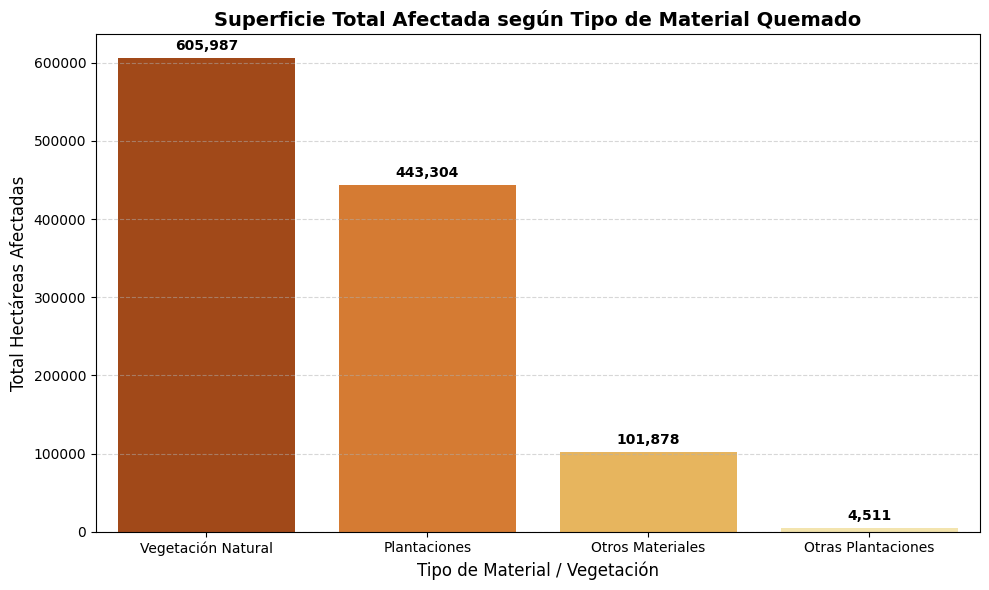

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Definir las columnas de materiales quemados
columnas_materiales = {
    'total_plan': 'Plantaciones',
    'total_veg': 'Vegetación Natural',
    'total_otra': 'Otros Materiales',
    'otras_plan': 'Otras Plantaciones'
}

# Sumar el total para cada tipo de material
totales_materiales = df[list(columnas_materiales.keys())].sum().reset_index()
totales_materiales.columns = ['Columna', 'Hectáreas']

# Mapear los nombres de las columnas a etiquetas legibles
totales_materiales['Material'] = totales_materiales['Columna'].map(columnas_materiales)
totales_materiales = totales_materiales.sort_values(by='Hectáreas', ascending=False)

# Crear el gráfico
plt.figure(figsize=(10, 6))
sns.barplot(data=totales_materiales, x='Material', y='Hectáreas', hue='Material', palette='YlOrBr_r', legend=False)

# Configurar títulos y etiquetas
plt.title('Superficie Total Afectada según Tipo de Material Quemado', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Material / Vegetación', fontsize=12)
plt.ylabel('Total Hectáreas Afectadas', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Mostrar los valores sobre cada barra
for index, row in totales_materiales.iterrows():
    plt.text(totales_materiales.index.get_loc(index), row['Hectáreas'] + (totales_materiales['Hectáreas'].max() * 0.01),
             f"{int(row['Hectáreas']):,}", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

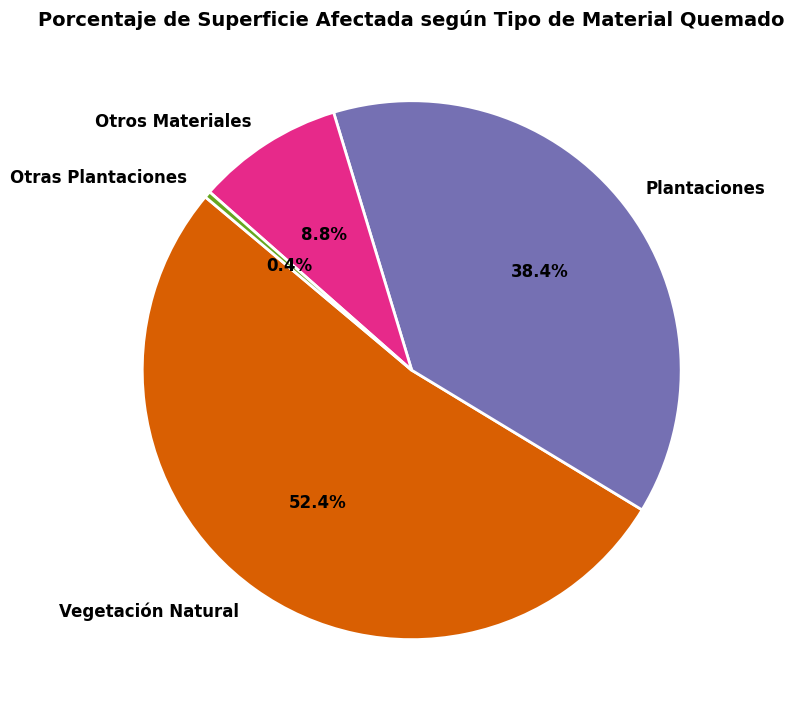

In [ ]:
import matplotlib.pyplot as plt

# Preparar los datos desde el DataFrame existente
etiquetas = totales_materiales['Material']
valores = totales_materiales['Hectáreas']

# Definir una paleta de colores atractiva
colores = ['#d95f02', '#7570b3', '#e7298a', '#66a61e']

# Crear el gráfico circular
plt.figure(figsize=(8, 8))
plt.pie(
    valores,
    labels=etiquetas,
    autopct='%1.1f%%',
    startangle=140,
    colors=colores,
    textprops={'fontsize': 12, 'weight': 'bold'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

# Título
plt.title('Porcentaje de Superficie Afectada según Tipo de Material Quemado', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

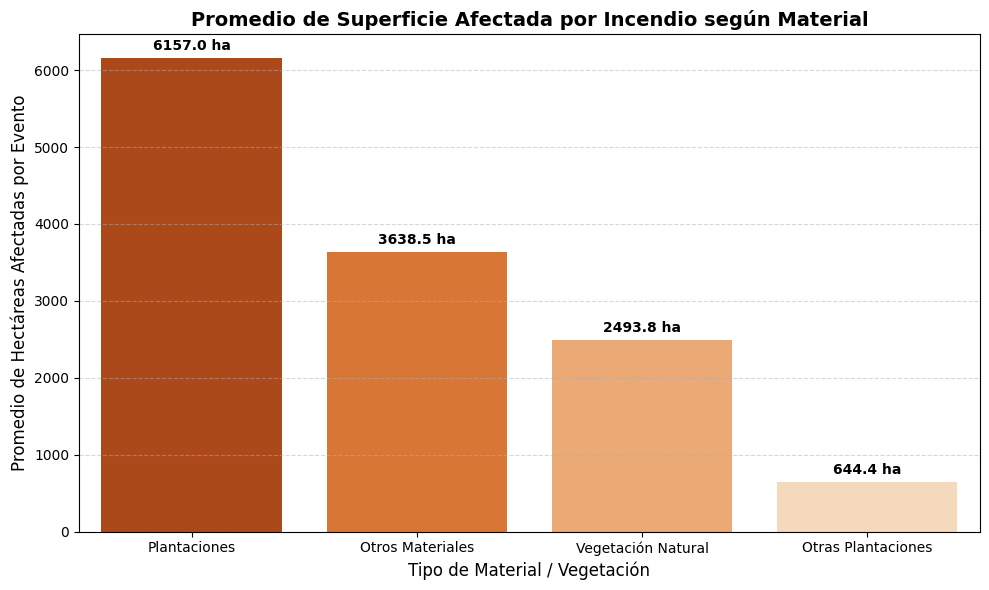

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Definir las columnas de materiales quemados
columnas_materiales = {
    'total_plan': 'Plantaciones',
    'total_veg': 'Vegetación Natural',
    'total_otra': 'Otros Materiales',
    'otras_plan': 'Otras Plantaciones'
}

# Calcular el promedio (media) omitiendo los valores en cero para evaluar el impacto medio real cuando ocurre el daño
# O si prefieres incluir los ceros, simplemente usa df[col].mean()
promediados = {}
for col, nombre in columnas_materiales.items():
    # Calculamos el promedio considerando solo los incendios que efectivamente afectaron ese material (> 0)
    datos_filtrados = df[df[col] > 0][col]
    promediados[nombre] = datos_filtrados.mean() if not datos_filtrados.empty else 0

# Convertir a DataFrame para graficar
df_promedios = pd.DataFrame(list(promediados.items()), columns=['Material', 'Promedio Hectáreas'])
df_promedios = df_promedios.sort_values(by='Promedio Hectáreas', ascending=False)

# Crear el gráfico
plt.figure(figsize=(10, 6))
sns.barplot(data=df_promedios, x='Material', y='Promedio Hectáreas', hue='Material', palette='Oranges_r', legend=False)

# Detalles del gráfico
plt.title('Promedio de Superficie Afectada por Incendio según Material', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Material / Vegetación', fontsize=12)
plt.ylabel('Promedio de Hectáreas Afectadas por Evento', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Añadir valores sobre las barras
for index, row in df_promedios.iterrows():
    plt.text(df_promedios.index.get_loc(index), row['Promedio Hectáreas'] + (df_promedios['Promedio Hectáreas'].max() * 0.01),
             f"{row['Promedio Hectáreas']:.1f} ha", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

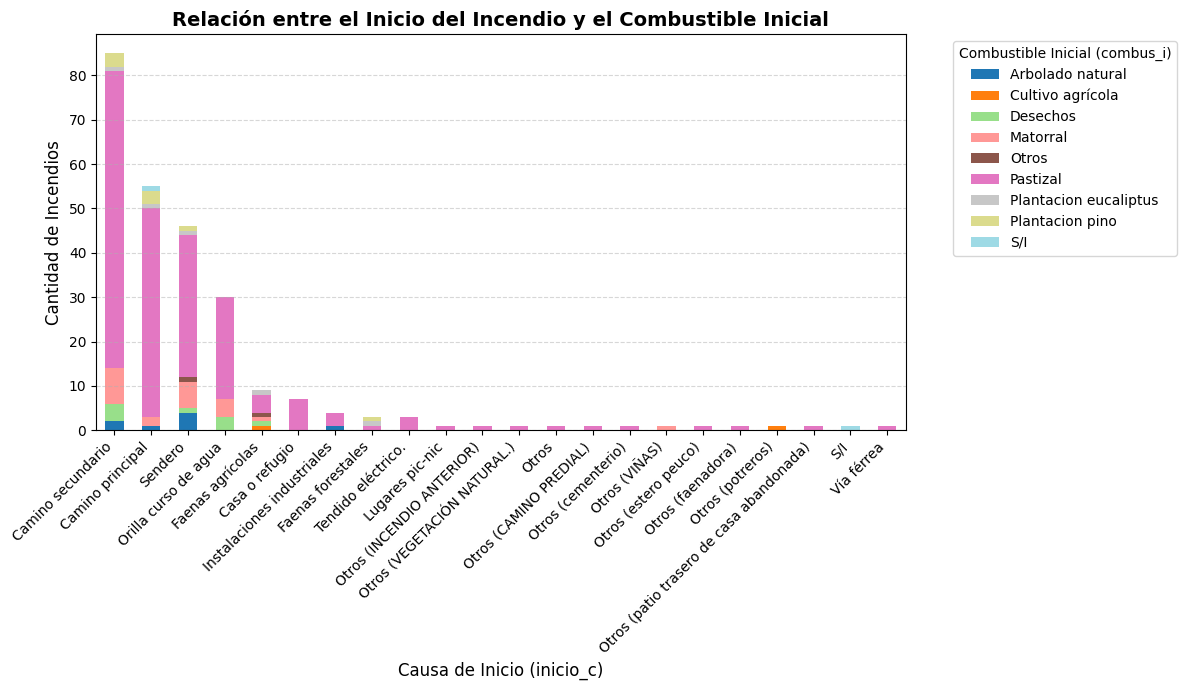

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Crear una tabla de contingencia cruzando 'inicio_c' (Inicio) y 'combus_i' (Combustible)
tabla_cruzada = pd.crosstab(df['inicio_c'], df['combus_i'])

# Ordenar la tabla por el volumen total para que el gráfico sea más claro
tabla_cruzada['Total'] = tabla_cruzada.sum(axis=1)
tabla_cruzada = tabla_cruzada.sort_values(by='Total', ascending=False).drop(columns='Total')

# Crear el gráfico de barras apiladas
fig, ax = plt.subplots(figsize=(12, 7))
tabla_cruzada.plot(kind='bar', stacked=True, ax=ax, cmap='tab20')

# Configurar títulos y etiquetas
plt.title('Relación entre el Inicio del Incendio y el Combustible Inicial', fontsize=14, fontweight='bold')
plt.xlabel('Causa de Inicio (inicio_c)', fontsize=12)
plt.ylabel('Cantidad de Incendios', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Combustible Inicial (combus_i)', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()